# RAG Assignment — Baseline Retrieval vs. Cross-Encoder Re-Ranking

This notebook builds two retrieval pipelines over the **same chunked corpus** and compares them:

| | Pipeline 1 — Baseline | Pipeline 2 — Re-ranking |
|---|---|---|
| Stage 1 | Bi-encoder retrieves Top 10 by cosine similarity | *same Top 10* |
| Stage 2 | — | Cross-encoder scores all 10 (query, chunk) pairs and re-sorts |
| To the LLM | Top 3 by cosine | Top 3 by cross-encoder score |
| Prompt | identical | identical |

Because the prompt, the LLM and the candidate pool are identical, **any difference between Answer 1 and Answer 2 comes only from which three chunks were selected.**

**Document:** Apple Inc. Form 10-K for fiscal 2024 (121 pages, ~64,000 words). It is long enough for the two retrievers to diverge, and it mixes very different kinds of text — financial statements, risk factors, debt indentures, employee stock plans, an insider trading policy and a compensation recovery policy. That mixture is what produces the failure cases studied in Section 7.

**Everything runs on CPU.** Threads are capped so the run does not monopolise the machine.

## 1. Setup and configuration

In [1]:
import os, re, json, time, uuid
os.environ.setdefault("OMP_NUM_THREADS", "6")      # keep the laptop usable while this runs

import numpy as np
import pandas as pd
import faiss
import torch
import pymupdf
import requests
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer
import transformers, huggingface_hub
transformers.logging.set_verbosity_error()
huggingface_hub.utils.logging.set_verbosity_error()

torch.set_num_threads(6)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

PDF_PATH        = "data/apple_10k_2024.pdf"
BI_ENCODER      = "sentence-transformers/all-MiniLM-L6-v2"     # bi-encoder for Stage 1
CROSS_ENCODER   = "cross-encoder/ms-marco-MiniLM-L-6-v2"       # cross-encoder for Stage 2 (as named in the brief)
LLM_MODEL       = "qwen2.5:3b"                                 # local model served by Ollama
OLLAMA_URL      = "http://localhost:11434/api/generate"

TOP_K_RETRIEVE  = 10      # candidates pulled by the bi-encoder
TOP_K_CONTEXT   = 3       # chunks handed to the LLM

MAX_CHUNK_TOKENS = 200    # see Section 2 for why this is measured in tokens, not words
OVERLAP_TOKENS   = 40

print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(), "| threads:", torch.get_num_threads())

torch 2.14.1+cpu | CUDA: False | threads: 6


## 2. Load the PDF and chunk it

**Chunk size is set in tokens, not words, on purpose.** `all-MiniLM-L6-v2` has a maximum input length of **256 tokens** and silently truncates anything longer. Financial tables and legal text tokenise far more densely than prose — in an earlier trial, 150-word chunks left **37 of 535 chunks (6.9%) over the limit**. Those chunks would have been partially invisible to the bi-encoder while fully visible to the cross-encoder (limit 512), which would have biased the comparison in the re-ranker's favour for a reason that has nothing to do with the method.

So chunks are packed sentence by sentence up to 200 tokens, with a 40-token overlap, and the limit is verified below. Every chunk keeps its page number(s) so results can be traced back to the document.

In [2]:
bi_encoder = SentenceTransformer(BI_ENCODER, device="cpu")
print("bi-encoder max input length:", bi_encoder.max_seq_length, "tokens")
# A separate copy of the same tokenizer, used only for counting. Its length cap is lifted so that
# measuring an over-long sentence (which is then split) doesn't trigger a truncation warning.
tokenizer  = AutoTokenizer.from_pretrained(BI_ENCODER, model_max_length=10**6)
n_tokens   = lambda s: len(tokenizer(s, add_special_tokens=False)["input_ids"])

def split_into_units(pdf_path):
    # Return (page, sentence) pairs. Over-long 'sentences' (tables, legal run-ons) are split by words.
    units = []
    for page_no, page in enumerate(pymupdf.open(pdf_path), start=1):
        text = re.sub(r"\s+", " ", page.get_text("text")).strip()
        for sent in re.split(r"(?<=[.!?;:])\s+(?=[A-Z(\"'0-9•])", text):
            sent = sent.strip()
            if not sent:
                continue
            if n_tokens(sent) <= MAX_CHUNK_TOKENS:
                units.append((page_no, sent))
                continue
            piece = []
            for word in sent.split():
                piece.append(word)
                if n_tokens(" ".join(piece)) >= MAX_CHUNK_TOKENS - 10:
                    units.append((page_no, " ".join(piece))); piece = []
            if piece:
                units.append((page_no, " ".join(piece)))
    return units

def build_chunks(units):
    # Pack sentences into chunks of at most MAX_CHUNK_TOKENS, carrying an overlap forward.
    chunks, current = [], []                       # current holds (page, sentence, token_count)
    total = lambda items: sum(n for *_, n in items)
    def emit():
        chunks.append({"id": len(chunks),
                       "text": " ".join(s for _, s, _ in current),
                       "pages": sorted({p for p, _, _ in current})})
    for page_no, sent in units:
        n = n_tokens(sent)
        if current and total(current) + n > MAX_CHUNK_TOKENS:
            emit()
            overlap = []
            for item in reversed(current):
                if total(overlap) + item[2] > OVERLAP_TOKENS:
                    break
                overlap.insert(0, item)
            current = overlap
        current.append((page_no, sent, n))
    if current:
        emit()
    return chunks

t0 = time.perf_counter()
chunks = build_chunks(split_into_units(PDF_PATH))
print(f"{len(chunks)} chunks built in {time.perf_counter() - t0:.1f}s")

lengths = [len(tokenizer(c["text"])["input_ids"]) for c in chunks]      # includes [CLS]/[SEP]
print(f"tokens per chunk: min {min(lengths)}, median {int(np.median(lengths))}, max {max(lengths)}")
print(f"chunks over the 256-token bi-encoder limit: {sum(l > 256 for l in lengths)}")
assert max(lengths) <= 256, "a chunk would be truncated by the bi-encoder"

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

bi-encoder max input length: 256 tokens


547 chunks built in 0.7s
tokens per chunk: min 37, median 180, max 229
chunks over the 256-token bi-encoder limit: 0


## 3. Stage 1 index — bi-encoder embeddings in FAISS

Each chunk is embedded **independently** of any query. Embeddings are L2-normalised, so an inner-product index (`IndexFlatIP`) returns exactly the cosine similarity. With ~550 chunks an exact (flat) index is instant; approximate indexes would add error and buy nothing at this scale.

In [3]:
t0 = time.perf_counter()
chunk_embeddings = bi_encoder.encode([c["text"] for c in chunks], batch_size=64,
                                     normalize_embeddings=True, show_progress_bar=False).astype("float32")
index = faiss.IndexFlatIP(chunk_embeddings.shape[1])
index.add(chunk_embeddings)
print(f"embedded {len(chunks)} chunks -> {chunk_embeddings.shape} in {time.perf_counter() - t0:.1f}s")
print(f"index holds {index.ntotal} vectors")

embedded 547 chunks -> (547, 384) in 16.0s
index holds 547 vectors


## 4. Pipeline 1 — baseline retrieval

In [4]:
def retrieve(query, k=TOP_K_RETRIEVE):
    # Bi-encoder Stage 1: embed the query alone, return the top-k chunk ids and cosine scores.
    q = bi_encoder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    return [int(i) for i in ids[0]], [float(s) for s in scores[0]]

def pipeline_1(query):
    # Baseline: take the Top 3 of the bi-encoder's Top 10 directly.
    ids, scores = retrieve(query)
    return {"top10": ids, "top10_scores": scores, "context": ids[:TOP_K_CONTEXT]}

## 5. Pipeline 2 — cross-encoder re-ranking

The cross-encoder reads the query and a chunk **together**, so every query token can attend to every chunk token. That is why it can tell "employees may **not** hedge Apple stock" apart from "Apple **does** hedge foreign currency" even though both are about hedging — something a single pre-computed chunk vector struggles to do. The price is that it must run once per (query, chunk) pair at query time, which is why it only sees the 10 candidates.

In [5]:
cross_encoder = CrossEncoder(CROSS_ENCODER, device="cpu")

def rerank(query, candidate_ids):
    # Score every (query, chunk) pair jointly and sort descending by cross-encoder score.
    scores = cross_encoder.predict([(query, chunks[i]["text"]) for i in candidate_ids])
    order = np.argsort(-scores)
    return [candidate_ids[j] for j in order], [float(scores[j]) for j in order]

def pipeline_2(query):
    # Re-ranking: same Top 10 as the baseline, re-sorted by the cross-encoder, then Top 3.
    base = pipeline_1(query)
    ids, scores = rerank(query, base["top10"])
    return {"top10": ids, "top10_scores": scores, "context": ids[:TOP_K_CONTEXT], "baseline_top10": base["top10"]}

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

## 6. The LLM and the shared prompt

Both pipelines use **this one prompt function**, so the only thing that differs between Answer 1 and Answer 2 is the three chunks inserted into it. **Temperature is 0** — with sampling, two runs on identical context could disagree, and the comparison would partly measure randomness rather than retrieval.

The model is told to answer only from the context and to say so if the context is insufficient. That makes a missing chunk visible as an "I don't know" or a wrong answer, which is exactly what Section 9 looks for.

In [6]:
PROMPT = '''You are answering questions about Apple Inc.'s fiscal 2024 Form 10-K.
Use ONLY the context below. If the context does not contain the answer, say "The context does not contain this information."
Answer in 2-3 sentences.

Context:
{context}

Question: {question}
Answer:'''

def build_prompt(question, chunk_ids):
    context = "\n\n".join(f"[Chunk {i}, page {chunks[i]['pages'][0]}] {chunks[i]['text']}" for i in chunk_ids)
    return PROMPT.format(context=context, question=question)

def generate(prompt, nocache=False):
    # Returns (answer, stats). With nocache=True a unique request id is prepended, so Ollama cannot
    # reuse a previously processed prompt - used only for latency measurement (Section 10).
    if nocache:
        prompt = f"[request {uuid.uuid4().hex}]\n" + prompt
    t0 = time.perf_counter()
    r = requests.post(OLLAMA_URL, json={
        "model": LLM_MODEL, "prompt": prompt, "stream": False,
        "options": {"temperature": 0, "num_ctx": 4096, "num_predict": 200, "num_thread": 6}},
        timeout=900)
    r.raise_for_status()
    j = r.json()
    stats = {"ms": (time.perf_counter() - t0) * 1000,
             "prefill ms": j.get("prompt_eval_duration", 0) / 1e6, "decode ms": j.get("eval_duration", 0) / 1e6,
             "prompt tokens evaluated": j.get("prompt_eval_count", 0), "answer tokens": j.get("eval_count", 0)}
    return j["response"].strip(), stats

print(requests.get("http://localhost:11434/api/version", timeout=5).json(), "- Ollama is reachable")

{'version': '0.40.3'} - Ollama is reachable


### A first look — one query through both pipelines

In [7]:
demo_q = "Who serves as Apple's Insider Trading Compliance Officer?"
p1, p2 = pipeline_1(demo_q), pipeline_2(demo_q)

pd.DataFrame({
    "rank": range(1, 11),
    "baseline chunk": p1["top10"], "cosine": np.round(p1["top10_scores"], 3),
    "re-ranked chunk": p2["top10"], "cross-enc score": np.round(p2["top10_scores"], 2),
})

,rank,baseline chunk,cosine,re-ranked chunk,cross-enc score
0,1,518,0.702,516,8.56
1,2,506,0.685,522,6.66
2,3,517,0.658,518,5.99
3,4,523,0.655,517,5.40
4,5,522,0.655,521,4.65
5,6,521,0.634,523,3.31
6,7,516,0.627,506,1.44
7,8,266,0.621,238,0.49
8,9,7,0.614,266,-6.16
9,10,238,0.614,7,-8.26


## 7. Failure-mode queries

Each query has a **gold chunk set** — the chunk(s) that actually contain the answer, found by reading the document. For each query we record the best gold rank under the baseline and after re-ranking.

The set has three parts:

1. **Rescues** — the gold chunk sits at rank 4–10 under the baseline (so it never reaches the LLM) and the cross-encoder promotes it into the Top 3. These cover the four categories in the brief.
2. **Controls** — queries whose wording closely matches the answer, where the baseline already works. They show the bi-encoder is not simply broken.
3. **Where re-ranking does not help** — reported deliberately. A comparison in which every query improves would not be believable.

In [8]:
QUERIES = [
    # (id, part, category, query, gold chunk ids, key fact the answer must contain)
    ("Q1", "rescue",  "Buried chunk (rank 4-10)",
     "Who serves as Apple's Insider Trading Compliance Officer?", [516], "General Counsel"),
    ("Q2", "rescue",  "Exception / corner case",
     "Is iPhone's share of net sales the same in every geographic region?", [170], "Greater China"),
    ("Q3", "rescue",  "Keyword trap / distractor",
     "Are puts and calls on Apple stock restricted for insiders?", [508, 509], "prohibited"),
    ("Q4", "rescue",  "Negation & constraints",
     "Which employees are not allowed to pledge Apple stock?", [509], "executive officers"),
    ("Q5", "rescue",  "Keyword trap / distractor",
     "How is incentive-based compensation defined for clawback purposes?", [539], "financial reporting measure"),
    ("Q6", "control", "Control (wording matches)",
     "Can Apple's executive officers pledge Apple stock as collateral for a loan?", [509], "prohibited"),
    ("Q7", "control", "Control (wording matches)",
     "Why did sales in China fall in 2024?", [122], "iPhone"),
    ("Q8", "no help", "Recall failure",
     "How many full-time equivalent employees did Apple have?", [25], "164,000"),
    ("Q9", "no help", "Keyword trap - both fail",
     "Can shares be pledged?", [509], "executive officers"),
    ("Q10","no help", "Re-ranking hurts",
     "When is Apple excused from clawing back executive pay?", [543], "burdensome"),
]

def best_rank(ranked_ids, gold):
    hits = [ranked_ids.index(g) + 1 for g in gold if g in ranked_ids]
    return min(hits) if hits else None

results = []
for qid, part, cat, q, gold, fact in QUERIES:
    p1, p2 = pipeline_1(q), pipeline_2(q)
    b, r = best_rank(p1["top10"], gold), best_rank(p2["top10"], gold)
    results.append({"id": qid, "part": part, "category": cat, "query": q, "gold": gold,
                    "baseline rank": b, "re-ranked rank": r,
                    "baseline top3": p1["context"], "re-ranked top3": p2["context"],
                    "p1": p1, "p2": p2, "fact": fact})

def verdict(b, r):
    inb, inr = (b is not None and b <= 3), (r is not None and r <= 3)
    if not inb and inr: return "RESCUED into Top 3"
    if inb and inr:     return "both in Top 3"
    if inb and not inr: return "HURT - dropped out"
    return "neither in Top 3"

rank_table = pd.DataFrame([{
    "id": x["id"], "category": x["category"], "gold chunk": x["gold"],
    "baseline rank": x["baseline rank"] or "not in Top 10",
    "re-ranked rank": x["re-ranked rank"] or "not in Top 10",
    "shift": (f"#{x['baseline rank']} -> #{x['re-ranked rank']}"
              if x["baseline rank"] and x["re-ranked rank"] else "-"),
    "outcome": verdict(x["baseline rank"], x["re-ranked rank"]),
} for x in results])
rank_table

,id,category,gold chunk,baseline rank,re-ranked rank,shift,outcome
0,Q1,Buried chunk (rank 4-10),[516],7,1,#7 -> #1,RESCUED into Top 3
1,Q2,Exception / corner case,[170],5,1,#5 -> #1,RESCUED into Top 3
2,Q3,Keyword trap / distractor,"[508, 509]",7,1,#7 -> #1,RESCUED into Top 3
3,Q4,Negation & constraints,[509],7,2,#7 -> #2,RESCUED into Top 3
4,Q5,Keyword trap / distractor,[539],5,1,#5 -> #1,RESCUED into Top 3
5,Q6,Control (wording matches),[509],1,1,#1 -> #1,both in Top 3
6,Q7,Control (wording matches),[122],1,1,#1 -> #1,both in Top 3
7,Q8,Recall failure,[25],not in Top 10,not in Top 10,-,neither in Top 3
8,Q9,Keyword trap - both fail,[509],not in Top 10,not in Top 10,-,neither in Top 3
9,Q10,Re-ranking hurts,[543],7,9,#7 -> #9,neither in Top 3


## 8. Rank-shift detail

For each query: which chunks each pipeline actually sent to the LLM, and where the gold chunk sat. A gold chunk outside the baseline's Top 3 never reaches the LLM, however highly the bi-encoder ranked it within the Top 10.

In [9]:
def describe(cid):
    c = chunks[cid]
    return f"chunk {cid} (p.{c['pages'][0]}): {c['text'][:95]}..."

for x in results:
    print("=" * 110)
    print(f"{x['id']}  [{x['category']}]  {x['query']}")
    print(f"gold {x['gold']}   baseline rank {x['baseline rank']}  ->  re-ranked rank {x['re-ranked rank']}"
          f"   ({verdict(x['baseline rank'], x['re-ranked rank'])})")
    print("  Baseline Top 3:")
    for cid in x["baseline top3"]:  print("    " + ("*" if cid in x["gold"] else " ") + " " + describe(cid))
    print("  Re-ranked Top 3:")
    for cid in x["re-ranked top3"]: print("    " + ("*" if cid in x["gold"] else " ") + " " + describe(cid))
print("=" * 110, "\n(* = gold chunk)")

Q1  [Buried chunk (rank 4-10)]  Who serves as Apple's Insider Trading Compliance Officer?
gold [516]   baseline rank 7  ->  re-ranked rank 1   (RESCUED into Top 3)
  Baseline Top 3:
      chunk 518 (p.112): An Insider Trading Compliance Officer may not trade in Apple securities unless another Insider ...
      chunk 506 (p.109): Trading while aware of material nonpublic information is a crime. Penalties for insider trading...
      chunk 517 (p.112): These individuals and their covered family members and entities are referred to as “Designated ...
  Re-ranked Top 3:
    * chunk 516 (p.112): restrictions that apply to you under this policy; provided, however, that in all other instance...
      chunk 522 (p.113): Apple’s Insider Trading Compliance Officer may impose such other conditions on the implementati...
      chunk 518 (p.112): An Insider Trading Compliance Officer may not trade in Apple securities unless another Insider ...
Q2  [Exception / corner case]  Is iPhone's share of net

### What the baseline retrieved instead

For the keyword-trap queries the interesting thing is *what* outranked the answer. Q9 shows four near-identical RSU award agreements, each saying unvested shares "shall not be … **pledged**", pushing the actual answer — the insider trading policy's pledging ban for directors and executives — out of the Top 10 entirely.

In [10]:
for qid in ["Q3", "Q9"]:
    x = next(r for r in results if r["id"] == qid)
    print(f"{qid}: {x['query']}   (gold {x['gold']})")
    for rank, (cid, s) in enumerate(zip(x["p1"]["top10"], x["p1"]["top10_scores"]), start=1):
        flag = "  <== GOLD" if cid in x["gold"] else ""
        print(f"  #{rank:2d}  cos {s:.3f}  {describe(cid)[:100]}{flag}")
    print()

Q3: Are puts and calls on Apple stock restricted for insiders?   (gold [508, 509])
  # 1  cos 0.611  chunk 511 (p.110): Information should be considered nonpublic for at least 24 hours after it has bee
  # 2  cos 0.592  chunk 521 (p.113): • does not permit you to exercise any subsequent influence over how, when, or whe
  # 3  cos 0.590  chunk 523 (p.113): Compliance of a Trading Plan with the terms of Rule 10b5-1 and the execution of t
  # 4  cos 0.589  chunk 506 (p.109): Trading while aware of material nonpublic information is a crime. Penalties for i
  # 5  cos 0.576  chunk 518 (p.112): An Insider Trading Compliance Officer may not trade in Apple securities unless an
  # 6  cos 0.562  chunk 514 (p.111): If you are notified about a special or extended restricted trading period, you sh
  # 7  cos 0.560  chunk 509 (p.109): If you are subject to a restricted trading period, you must not buy or sell Apple  <== GOLD
  # 8  cos 0.549  chunk 522 (p.113): Apple’s Insider Trading Compliance Of

## 9. Answer 1 vs. Answer 2

Every query is sent through the identical prompt twice — once with the baseline's Top 3, once with the re-ranked Top 3. This runs the local LLM 20 times, roughly 10 minutes on CPU.

The table below is only a first-pass **screen**: does the answer contain the key fact from the gold chunk? It is not a verdict. Q5 shows why — Answer 1 contains the phrase "financial reporting measure" yet misstates the definition. The authoritative judgement is the manual assessment after the answers are printed.

In [11]:
t0 = time.perf_counter()
for x in results:
    x["answer 1"], _ = generate(build_prompt(x["query"], x["baseline top3"]))
    x["answer 2"], _ = generate(build_prompt(x["query"], x["re-ranked top3"]))
print(f"generated {2 * len(results)} answers in {(time.perf_counter() - t0) / 60:.1f} min")

has_fact = lambda answer, fact: fact.lower() in answer.lower()
answer_table = pd.DataFrame([{
    "id": x["id"], "category": x["category"],
    "Answer 1 contains key fact": has_fact(x["answer 1"], x["fact"]),
    "Answer 2 contains key fact": has_fact(x["answer 2"], x["fact"]),
    "key fact": x["fact"],
} for x in results])
answer_table

generated 20 answers in 1.6 min


,id,category,Answer 1 contains key fact,Answer 2 contains key fact,key fact
0,Q1,Buried chunk (rank 4-10),False,True,General Counsel
1,Q2,Exception / corner case,False,False,Greater China
2,Q3,Keyword trap / distractor,False,True,prohibited
3,Q4,Negation & constraints,False,True,executive officers
4,Q5,Keyword trap / distractor,True,True,financial reporting measure
5,Q6,Control (wording matches),True,True,prohibited
6,Q7,Control (wording matches),True,True,iPhone
7,Q8,Recall failure,False,False,"164,000"
8,Q9,Keyword trap - both fail,False,False,executive officers
9,Q10,Re-ranking hurts,False,False,burdensome


In [12]:
for x in results:
    print("=" * 110)
    print(f"{x['id']}  {x['query']}")
    print(f"   key fact: '{x['fact']}'   gold rank {x['baseline rank']} -> {x['re-ranked rank']}")
    print(f"\n   ANSWER 1 (baseline Top 3 {x['baseline top3']}):\n   {x['answer 1']}")
    print(f"\n   ANSWER 2 (re-ranked Top 3 {x['re-ranked top3']}):\n   {x['answer 2']}")
print("=" * 110)

Q1  Who serves as Apple's Insider Trading Compliance Officer?
   key fact: 'General Counsel'   gold rank 7 -> 1

   ANSWER 1 (baseline Top 3 [518, 506, 517]):
   The context does not contain this information.

   ANSWER 2 (re-ranked Top 3 [516, 522, 518]):
   Apple’s General Counsel and one or more authorized delegates serve as Apple’s Insider Trading Compliance Officer. Members of the Board of Directors, executive officers and certain other individuals designated by Apple’s Insider Trading Compliance Officer, and family members who reside with them or are financially dependent on them, and any other person or entity who such individuals direct, influence, or control (or may be reasonably perceived to direct, influence, or control), are subject to additional restrictions. These individuals and their covered family members and entities are referred to as “Designated Individuals.”
Q2  Is iPhone's share of net sales the same in every geographic region?
   key fact: 'Greater China'   gold 

### Manual assessment

Each answer was read against its gold chunk and labelled.

*Reproducibility:* temperature 0 makes generation deterministic in substance but not always to the word on CPU. Across three full runs, 14 of the 20 answers were word-for-word identical every time; the rest varied only in phrasing, and every label below held in all three runs. Categories follow the brief: an **omission** leaves out the answer (here, usually by correctly saying the context lacks it), a **misstatement** gets the rule wrong, and a **hallucination** asserts something the document does not say.

In [13]:
ASSESSMENT = {
    "Q1":  ("Omission - abstained ('not in context')",
            "Correct - names Apple's General Counsel"),
    "Q2":  ("Omission - abstained",
            "Omission - the gold chunk was ranked #1, but the model missed the 'except in Greater China' clause"),
    "Q3":  ("Omission - abstained",
            "Correct - puts and calls are prohibited at all times"),
    "Q4":  ("Omission - abstained",
            "Correct - Board members and executive officers"),
    "Q5":  ("Misstatement - describes which awards are in scope and when they count as received, not what the term means",
            "Correct - gives the actual definition"),
    "Q6":  ("Correct, though it opens with a confusing 'Yes'",
            "Correct (identical answer)"),
    "Q7":  ("Mostly correct - names iPhone and iPad but calls the currency the primary cause",
            "Mostly correct - same issue"),
    "Q8":  ("Omission - abstained (gold chunk never retrieved)",
            "Omission - abstained"),
    "Q9":  ("Omission - abstained",
            "Wrong - says shares CAN be pledged while quoting text saying they cannot"),
    "Q10": ("Hallucination - 'Apple is not excused from clawing back'",
            "Hallucination - same claim"),
}
is_correct = lambda label: label.startswith(("Correct", "Mostly correct"))

assessment = pd.DataFrame([{
    "id": x["id"], "category": x["category"],
    "gold rank": f"{x['baseline rank'] or '-'} -> {x['re-ranked rank'] or '-'}",
    "Answer 1 (baseline)": ASSESSMENT[x["id"]][0],
    "Answer 2 (re-ranked)": ASSESSMENT[x["id"]][1],
} for x in results])
assessment

,id,category,gold rank,Answer 1 (baseline),Answer 2 (re-ranked)
0,Q1,Buried chunk (rank 4-10),7 -> 1,Omission - abstained ('not in context'),Correct - names Apple's General Counsel
1,Q2,Exception / corner case,5 -> 1,Omission - abstained,"Omission - the gold chunk was ranked #1, but the model missed the 'except in Greater China' clause"
2,Q3,Keyword trap / distractor,7 -> 1,Omission - abstained,Correct - puts and calls are prohibited at all times
3,Q4,Negation & constraints,7 -> 2,Omission - abstained,Correct - Board members and executive officers
4,Q5,Keyword trap / distractor,5 -> 1,"Misstatement - describes which awards are in scope and when they count as received, not what the term means",Correct - gives the actual definition
5,Q6,Control (wording matches),1 -> 1,"Correct, though it opens with a confusing 'Yes'",Correct (identical answer)
6,Q7,Control (wording matches),1 -> 1,Mostly correct - names iPhone and iPad but calls the currency the primary cause,Mostly correct - same issue
7,Q8,Recall failure,- -> -,Omission - abstained (gold chunk never retrieved),Omission - abstained
8,Q9,Keyword trap - both fail,- -> -,Omission - abstained,Wrong - says shares CAN be pledged while quoting text saying they cannot
9,Q10,Re-ranking hurts,7 -> 9,Hallucination - 'Apple is not excused from clawing back',Hallucination - same claim


## 10. Latency profiling

Each stage is timed separately over **20 repeats per query** after a warm-up pass, so model loading and first-call overhead are excluded. The headline comparison is **retrieval only** — the LLM costs the same in both pipelines and would swamp the difference. One LLM call per pipeline is timed separately for context.

In [14]:
def timed(fn, *args):
    t = time.perf_counter(); out = fn(*args); return out, (time.perf_counter() - t) * 1000

REPEATS = 20
timing_queries = [q for _, _, _, q, _, _ in QUERIES]
for q in timing_queries:                           # warm-up
    rerank(q, retrieve(q)[0])

rows = []
for q in timing_queries:
    for _ in range(REPEATS):
        t0 = time.perf_counter()
        qv = bi_encoder.encode([q], normalize_embeddings=True).astype("float32")
        t1 = time.perf_counter()
        _, ids = index.search(qv, TOP_K_RETRIEVE)
        t2 = time.perf_counter()
        rerank(q, [int(i) for i in ids[0]])
        t3 = time.perf_counter()
        rows.append({"query embed": (t1-t0)*1000, "FAISS search": (t2-t1)*1000, "cross-encode 10": (t3-t2)*1000})

lat = pd.DataFrame(rows)
lat["Pipeline 1 retrieval"] = lat["query embed"] + lat["FAISS search"]
lat["Pipeline 2 retrieval"] = lat["Pipeline 1 retrieval"] + lat["cross-encode 10"]
summary = lat.agg(["mean", "median", lambda s: s.quantile(0.95)]).T
summary.columns = ["mean (ms)", "median (ms)", "p95 (ms)"]
print(f"{len(lat)} timed runs ({len(timing_queries)} queries x {REPEATS} repeats)")
summary.round(2)

200 timed runs (10 queries x 20 repeats)


,mean (ms),median (ms),p95 (ms)
query embed,12.01,12.12,15.29
FAISS search,0.32,0.36,0.43
cross-encode 10,405.49,397.38,465.40
Pipeline 1 retrieval,12.33,12.48,15.68
Pipeline 2 retrieval,417.82,408.95,478.16


**LLM cost is measured with dedicated cold calls.** Ollama keeps previously processed prompts in a cache and reuses any matching prefix — including prompts sent by an *earlier run of this notebook*. An identical prompt then skips almost all of its processing and appears roughly ten times faster than it really is. To measure true cost, each timing call below is prefixed with a unique request id, so nothing can be reused. The answers analysed in Section 9 are unaffected; these calls exist only to be timed.

Ollama's own counters split each call into **prefill** (processing the prompt — similar in both pipelines, since both send three chunks) and **decode** (generating the answer — proportional to answer length, which differs: a "not in context" reply is a handful of tokens).

In [15]:
cold = []
for x in [r for r in results if r["part"] == "rescue"]:
    for name, key in (("Pipeline 1 - baseline", "baseline top3"), ("Pipeline 2 - re-ranking", "re-ranked top3")):
        _, st = generate(build_prompt(x["query"], x[key]), nocache=True)
        cold.append({"pipeline": name, **st})
cold = pd.DataFrame(cold)
assert cold["prompt tokens evaluated"].min() > 100, "a timing call hit the prompt cache"
llm_med = cold.groupby("pipeline").median(numeric_only=True)

p1_ret = summary.loc["Pipeline 1 retrieval", "median (ms)"]
p2_ret = summary.loc["Pipeline 2 retrieval", "median (ms)"]
end_to_end = pd.DataFrame({
    "retrieval (ms)":   [p1_ret, p2_ret],
    "LLM prefill (ms)": llm_med["prefill ms"].values,
    "LLM decode (ms)":  llm_med["decode ms"].values,
    "LLM total (ms)":   llm_med["ms"].values,
    "prompt tokens":    llm_med["prompt tokens evaluated"].values,
    "answer tokens":    llm_med["answer tokens"].values,
}, index=llm_med.index)
end_to_end["end to end (ms)"] = end_to_end["retrieval (ms)"] + end_to_end["LLM total (ms)"]
p2_total = end_to_end.loc["Pipeline 2 - re-ranking", "end to end (ms)"]
print(f"{len(cold)} cold LLM calls (5 rescue queries x 2 pipelines), medians shown")
print(f"re-ranking adds {p2_ret - p1_ret:.0f} ms to retrieval ({p2_ret / p1_ret:.0f}x the baseline), "
      f"which is {100 * (p2_ret - p1_ret) / p2_total:.1f}% of Pipeline 2's end-to-end time")
end_to_end.round(0)

10 cold LLM calls (5 rescue queries x 2 pipelines), medians shown
re-ranking adds 396 ms to retrieval (33x the baseline), which is 1.3% of Pipeline 2's end-to-end time


,retrieval (ms),LLM prefill (ms),LLM decode (ms),LLM total (ms),prompt tokens,answer tokens,end to end (ms)
pipeline,,,,,,,
Pipeline 1 - baseline,12.0,20864.0,727.0,21642.0,711.0,9.0,21655.0
Pipeline 2 - re-ranking,409.0,22107.0,3493.0,29149.0,742.0,38.0,29558.0


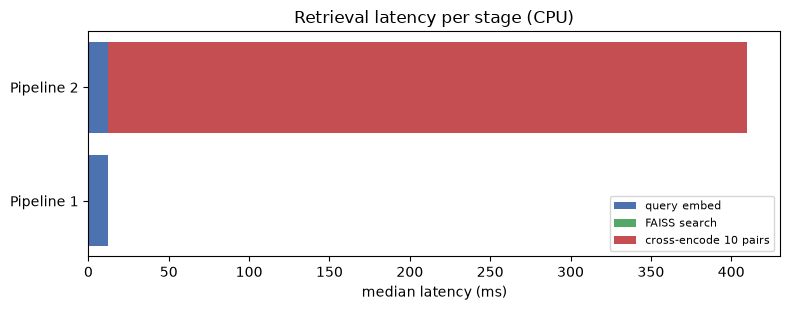

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.2))
stages = ["query embed", "FAISS search", "cross-encode 10"]
med = [summary.loc[s, "median (ms)"] for s in stages]
ax.barh(["Pipeline 1", "Pipeline 2"], [med[0], med[0]], color="#4C72B0", label="query embed")
ax.barh(["Pipeline 1", "Pipeline 2"], [med[1], med[1]], left=[med[0], med[0]], color="#55A868", label="FAISS search")
ax.barh(["Pipeline 2"], [med[2]], left=[med[0] + med[1]], color="#C44E52", label="cross-encode 10 pairs")
ax.set_xlabel("median latency (ms)"); ax.set_title("Retrieval latency per stage (CPU)")
ax.legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

## 11. The scaling question — measured

Why not skip the bi-encoder and run the cross-encoder over **every** chunk? Below, one query is cross-encoded against all chunks in this document and timed, against the 10 used by Pipeline 2, and both are extrapolated linearly to larger collections.

The two stages scale very differently. The cross-encoder must run a full transformer pass for **every** (query, chunk) pair at query time. The bi-encoder computes chunk embeddings once, offline; at query time it embeds only the query and does a vector search. A flat (exact) FAISS search does grow linearly with collection size, but each comparison is a single dot product, thousands of times cheaper than a transformer pass — and approximate indexes (HNSW, IVF) grow sub-linearly. The extrapolation below uses the flat index, i.e. the pessimistic case for the two-stage pipeline.

In [17]:
q = QUERIES[0][3]
all_ids = list(range(len(chunks)))
rerank(q, all_ids[:10])                                         # warm-up
_, t_10  = timed(rerank, q, all_ids[:10])
_, t_all = timed(rerank, q, all_ids)
per_pair = t_all / len(all_ids)

embed_ms  = summary.loc["query embed", "median (ms)"]
search_ms = summary.loc["FAISS search", "median (ms)"]
per_vec   = search_ms / index.ntotal                            # flat search cost per stored vector

print(f"cross-encoder, 10 pairs     : {t_10:9.1f} ms")
print(f"cross-encoder, {len(all_ids)} pairs    : {t_all:9.1f} ms   ({per_pair:.2f} ms per pair)")
print(f"bi-encoder: embed query     : {embed_ms:9.2f} ms   (chunk vectors precomputed offline)")
print(f"bi-encoder: flat search     : {search_ms:9.2f} ms   ({per_vec * 1000:.2f} microseconds per vector)")
print(f"one cross-encoder pair costs as much as ~{per_pair / per_vec:,.0f} vector comparisons")

scale = pd.DataFrame({"chunks in collection": [len(chunks), 10_000, 100_000, 1_000_000]})
n = scale["chunks in collection"]
scale["cross-encode everything"] = (n * per_pair / 1000).map(lambda s: f"{s:,.1f} s" if s < 3600 else f"{s / 3600:,.1f} h")
scale["two-stage (flat index)"] = ((embed_ms + n * per_vec + t_10) / 1000).map(lambda s: f"{s:.2f} s")
scale

cross-encoder, 10 pairs     :     360.2 ms
cross-encoder, 547 pairs    :   22682.2 ms   (41.47 ms per pair)
bi-encoder: embed query     :     12.12 ms   (chunk vectors precomputed offline)
bi-encoder: flat search     :      0.36 ms   (0.66 microseconds per vector)
one cross-encoder pair costs as much as ~63,064 vector comparisons


,chunks in collection,cross-encode everything,two-stage (flat index)
0,547,22.7 s,0.37 s
1,10000,414.7 s,0.38 s
2,100000,1.2 h,0.44 s
3,1000000,11.5 h,1.03 s


## 12. Summary of measured results

In [18]:
rescued = [x for x in results if verdict(x["baseline rank"], x["re-ranked rank"]) == "RESCUED into Top 3"]
print(f"Chunks: {len(chunks)}   Queries: {len(results)}   Rescued into Top 3: {len(rescued)}")
for x in rescued:
    print(f"  {x['id']} {x['category']:28s} #{x['baseline rank']} -> #{x['re-ranked rank']}")
rescue_ids = [x["id"] for x in results if x["part"] == "rescue"]
c1 = sum(is_correct(ASSESSMENT[i][0]) for i in rescue_ids)
c2 = sum(is_correct(ASSESSMENT[i][1]) for i in rescue_ids)
print(f"\nCorrect answers on the {len(rescue_ids)} rescue queries - Answer 1: {c1}/{len(rescue_ids)}   Answer 2: {c2}/{len(rescue_ids)}")
print(f"Correct answers on all {len(results)} queries      - Answer 1: "
      f"{sum(is_correct(a) for a, _ in ASSESSMENT.values())}/{len(results)}   Answer 2: "
      f"{sum(is_correct(b) for _, b in ASSESSMENT.values())}/{len(results)}")
print(f"Median retrieval - Pipeline 1: {p1_ret:.1f} ms   Pipeline 2: {p2_ret:.1f} ms")
print(f"Cross-encoding all {len(chunks)} chunks for one query: {t_all/1000:.1f} s (vs {t_10:.0f} ms for 10)")

Chunks: 547   Queries: 10   Rescued into Top 3: 5
  Q1 Buried chunk (rank 4-10)     #7 -> #1
  Q2 Exception / corner case      #5 -> #1
  Q3 Keyword trap / distractor    #7 -> #1
  Q4 Negation & constraints       #7 -> #2
  Q5 Keyword trap / distractor    #5 -> #1

Correct answers on the 5 rescue queries - Answer 1: 0/5   Answer 2: 4/5
Correct answers on all 10 queries      - Answer 1: 2/10   Answer 2: 6/10
Median retrieval - Pipeline 1: 12.5 ms   Pipeline 2: 408.9 ms
Cross-encoding all 547 chunks for one query: 22.7 s (vs 360 ms for 10)
